In [1]:
import pandas as pd
import optuna

from pathlib import Path
from sklearn.model_selection import KFold, cross_val_score

# Localiser le projet
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Charger les partitions déjà enregistrées
splits_dir = project_dir / "data" / "splits"

train_df = pd.read_csv(splits_dir / "train.csv")
val_df = pd.read_csv(splits_dir / "validation.csv")

# Séparer les variables explicatives et la cible
target = "MedHouseVal"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_val = val_df.drop(columns=[target])
y_val = val_df[target]

print("Version Optuna :", optuna.__version__)
print("Train :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)

c:\5IASD\DEVELOPPEMENT DES APPLICATION INTELLIGENTES\TP\TP2-PREDICTION-PRIX-IMMOBILIER\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Version Optuna : 5.0.0
Train : (14448, 8) (14448,)
Validation : (3096, 8) (3096,)


In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Définir une validation croisée à 5 folds
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Recréer HistGBM avec les paramètres initiaux
modele = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    early_stopping=False,
    random_state=42
)

# Évaluer avec validation croisée
scores = cross_val_score(
    modele,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

# Scikit-learn retourne des scores négatifs
mae_folds = -scores

print("MAE par fold :", mae_folds.round(4))
print(f"MAE moyenne CV : {mae_folds.mean():.4f}")
print(f"Écart-type CV  : {mae_folds.std():.4f}")

MAE par fold : [0.3004 0.3171 0.2981 0.2991 0.2998]
MAE moyenne CV : 0.3029
Écart-type CV  : 0.0072


In [3]:
import optuna
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score

def objective(trial):

    # 1. Optuna propose une configuration
    params = {
        "max_iter": trial.suggest_int(
            "max_iter", 100, 500, step=50
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.2, log=True
        ),

        "max_leaf_nodes": trial.suggest_int(
            "max_leaf_nodes", 15, 63
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 5, 40
        ),

        "l2_regularization": trial.suggest_float(
            "l2_regularization", 0.0, 2.0
        )
    }

    # 2. Construire le modèle avec ces paramètres
    modele = HistGradientBoostingRegressor(
        **params,
        early_stopping=False,
        random_state=42
    )

    # 3. Évaluer la configuration sur 5 folds
    scores = cross_val_score(
        modele,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    # 4. Retrouver les MAE positives
    mae_folds = -scores

    # 5. Enregistrer la dispersion des résultats
    trial.set_user_attr(
        "mae_std",
        float(mae_folds.std())
    )

    # 6. Retourner la MAE moyenne à Optuna
    return float(mae_folds.mean())

In [4]:
# Assurer la reproductibilité de la recherche
sampler = optuna.samplers.TPESampler(seed=42)

# Créer l'étude
study_histgbm = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    study_name="optimisation_histgbm"
)

# Lancer 20 essais
study_histgbm.optimize(
    objective,
    n_trials=20
)

# Afficher la meilleure configuration
print("\nMeilleure MAE moyenne CV :")
print(round(study_histgbm.best_value, 4))

print("\nMeilleurs hyperparamètres :")
for param, valeur in study_histgbm.best_params.items():
    print(f"{param} : {valeur}")

[I 2026-11-10 13:06:15,583] A new study created in memory with name: optimisation_histgbm
[I 2026-11-10 13:06:18,970] Trial 0 finished with value: 0.3028391141440803 and parameters: {'max_iter': 250, 'learning_rate': 0.1785436060870726, 'max_leaf_nodes': 50, 'min_samples_leaf': 26, 'l2_regularization': 0.31203728088487304}. Best is trial 0 with value: 0.3028391141440803.
[I 2026-11-10 13:06:21,725] Trial 1 finished with value: 0.33965102715769957 and parameters: {'max_iter': 150, 'learning_rate': 0.022861967752626437, 'max_leaf_nodes': 57, 'min_samples_leaf': 26, 'l2_regularization': 1.416145155592091}. Best is trial 0 with value: 0.3028391141440803.
[I 2026-11-10 13:06:24,801] Trial 2 finished with value: 0.305944355146867 and parameters: {'max_iter': 100, 'learning_rate': 0.18661212048851336, 'max_leaf_nodes': 55, 'min_samples_leaf': 12, 'l2_regularization': 0.36364993441420124}. Best is trial 0 with value: 0.3028391141440803.
[I 2026-11-10 13:06:30,133] Trial 3 finished with value: 


Meilleure MAE moyenne CV :
0.2957

Meilleurs hyperparamètres :
max_iter : 500
learning_rate : 0.08585558842037842
max_leaf_nodes : 39
min_samples_leaf : 10
l2_regularization : 1.5572418364144454


In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor
from time import perf_counter

# 1. Récupérer les meilleurs hyperparamètres
best_params = study_histgbm.best_params

# 2. Créer un nouveau modèle
histgbm_optimise = HistGradientBoostingRegressor(
    **best_params,
    early_stopping=False,
    random_state=42
)

# 3. Entraîner sur l'ensemble du Train
debut = perf_counter()

histgbm_optimise.fit(X_train, y_train)

temps_histgbm_opt = perf_counter() - debut

# 4. Effectuer les prédictions
y_pred_train_opt = histgbm_optimise.predict(X_train)
y_pred_val_opt = histgbm_optimise.predict(X_val)

print(f"Temps d'entraînement : {temps_histgbm_opt:.2f} s")

print("\nMeilleurs paramètres :")
print(best_params)

print("\nPremières prédictions :")
print(y_pred_val_opt[:5])

Temps d'entraînement : 1.16 s

Meilleurs paramètres :
{'max_iter': 500, 'learning_rate': 0.08585558842037842, 'max_leaf_nodes': 39, 'min_samples_leaf': 10, 'l2_regularization': 1.5572418364144454}

Premières prédictions :
[1.70202934 1.21364721 2.41487623 3.1217245  1.18329109]


In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)
import pandas as pd

# Métriques sur Train
mae_train_opt = mean_absolute_error(
    y_train, y_pred_train_opt
)

rmse_train_opt = root_mean_squared_error(
    y_train, y_pred_train_opt
)

r2_train_opt = r2_score(
    y_train, y_pred_train_opt
)

# Métriques sur Validation externe
mae_val_opt = mean_absolute_error(
    y_val, y_pred_val_opt
)

rmse_val_opt = root_mean_squared_error(
    y_val, y_pred_val_opt
)

r2_val_opt = r2_score(
    y_val, y_pred_val_opt
)

# Comparaison Train / Validation
resultats_optimises = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [
        mae_train_opt,
        rmse_train_opt,
        r2_train_opt
    ],
    "Validation": [
        mae_val_opt,
        rmse_val_opt,
        r2_val_opt
    ]
})

display(resultats_optimises.round(4))

print(f"\nMAE Validation : {mae_val_opt * 100000:,.2f} $")

,Métrique,Train,Validation
0,MAE,0.1574,0.2945
1,RMSE,0.2222,0.4600
2,R²,0.9630,0.8419



MAE Validation : 29,452.31 $


In [7]:
import pandas as pd
import json
from pathlib import Path

# Dossier des rapports
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Résumé de l'optimisation
resume_histgbm = pd.DataFrame([{
    "Modele": "HistGBM_optimise",
    "Nombre_essais": len(study_histgbm.trials),
    "MAE_CV": study_histgbm.best_value,
    "MAE_Train": mae_train_opt,
    "MAE_Validation": mae_val_opt,
    "RMSE_Validation": rmse_val_opt,
    "R2_Validation": r2_val_opt,
    "Temps_entrainement_s": temps_histgbm_opt
}])

display(resume_histgbm.round(4))

# Sauvegarder les métriques
resume_histgbm.to_csv(
    reports_dir / "optimisation_histgbm_resume.csv",
    index=False
)

# Sauvegarder les meilleurs hyperparamètres
with open(
    reports_dir / "histgbm_best_params.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        study_histgbm.best_params,
        f,
        indent=4
    )

print("Résultats et hyperparamètres sauvegardés.")

,Modele,Nombre_essais,MAE_CV,MAE_Train,MAE_Validation,RMSE_Validation,R2_Validation,Temps_entrainement_s
0,HistGBM_optimise,20,0.2957,0.1574,0.2945,0.46,0.8419,1.1612


Résultats et hyperparamètres sauvegardés.


In [8]:
import optuna

from lightgbm import LGBMRegressor
from sklearn.model_selection import cross_val_score

def objective_lightgbm(trial):

    # 1. Optuna propose les hyperparamètres
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 100, 500, step=50
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.2, log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves", 15, 63
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples", 5, 40
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.0, 2.0
        )
    }

    # 2. Créer le modèle LightGBM
    modele = LGBMRegressor(
        **params,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    # 3. Validation croisée sur Train uniquement
    scores = cross_val_score(
        modele,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    # 4. Calculer la MAE
    mae_folds = -scores

    # 5. Sauvegarder l'écart-type
    trial.set_user_attr(
        "mae_std",
        float(mae_folds.std())
    )

    # 6. Retourner la MAE moyenne
    return float(mae_folds.mean())

In [9]:
# Sampler reproductible
sampler_lgbm = optuna.samplers.TPESampler(
    seed=42
)

# Créer l'étude
study_lightgbm = optuna.create_study(
    direction="minimize",
    sampler=sampler_lgbm,
    study_name="optimisation_lightgbm"
)

# Effectuer 20 essais
study_lightgbm.optimize(
    objective_lightgbm,
    n_trials=20
)

# Résultats
print("\nMeilleure MAE moyenne CV :")
print(round(study_lightgbm.best_value, 4))

print("\nMeilleurs hyperparamètres :")

for param, valeur in study_lightgbm.best_params.items():
    print(f"{param} : {valeur}")

[I 2026-11-10 13:20:24,556] A new study created in memory with name: optimisation_lightgbm
[I 2026-11-10 13:20:27,980] Trial 0 finished with value: 0.30434994429590534 and parameters: {'n_estimators': 250, 'learning_rate': 0.1785436060870726, 'num_leaves': 50, 'min_child_samples': 26, 'reg_lambda': 0.31203728088487304}. Best is trial 0 with value: 0.30434994429590534.
[I 2026-11-10 13:20:32,490] Trial 1 finished with value: 0.33971893460828706 and parameters: {'n_estimators': 150, 'learning_rate': 0.022861967752626437, 'num_leaves': 57, 'min_child_samples': 26, 'reg_lambda': 1.416145155592091}. Best is trial 0 with value: 0.30434994429590534.
[I 2026-11-10 13:20:34,374] Trial 2 finished with value: 0.3059722416665388 and parameters: {'n_estimators': 100, 'learning_rate': 0.18661212048851336, 'num_leaves': 55, 'min_child_samples': 12, 'reg_lambda': 0.36364993441420124}. Best is trial 0 with value: 0.30434994429590534.
[I 2026-11-10 13:20:36,436] Trial 3 finished with value: 0.3187154435


Meilleure MAE moyenne CV :
0.2954

Meilleurs hyperparamètres :
n_estimators : 500
learning_rate : 0.05951450131797417
num_leaves : 50
min_child_samples : 14
reg_lambda : 0.05502415853676508


In [10]:
from lightgbm import LGBMRegressor
from time import perf_counter

# 1. Récupérer les meilleurs hyperparamètres
best_params_lgbm = study_lightgbm.best_params

# 2. Créer un nouveau modèle LightGBM
lgbm_optimise = LGBMRegressor(
    **best_params_lgbm,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# 3. Entraîner sur 100 % du Train
debut = perf_counter()

lgbm_optimise.fit(X_train, y_train)

temps_lgbm_opt = perf_counter() - debut

# 4. Prédictions
y_pred_train_lgbm_opt = lgbm_optimise.predict(X_train)
y_pred_val_lgbm_opt = lgbm_optimise.predict(X_val)

print(f"Temps d'entraînement : {temps_lgbm_opt:.2f} s")

print("\nMeilleurs hyperparamètres :")
print(best_params_lgbm)

print("\nPremières prédictions :")
print(y_pred_val_lgbm_opt[:5])

Temps d'entraînement : 2.16 s

Meilleurs hyperparamètres :
{'n_estimators': 500, 'learning_rate': 0.05951450131797417, 'num_leaves': 50, 'min_child_samples': 14, 'reg_lambda': 0.05502415853676508}

Premières prédictions :
[1.817129   1.17549082 2.26850963 3.12574492 1.14407882]


In [12]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

import pandas as pd

# Métriques Train
mae_train_lgbm_opt = mean_absolute_error(
    y_train, y_pred_train_lgbm_opt
)

rmse_train_lgbm_opt = root_mean_squared_error(
    y_train, y_pred_train_lgbm_opt
)

r2_train_lgbm_opt = r2_score(
    y_train, y_pred_train_lgbm_opt
)

# Métriques Validation externe
mae_val_lgbm_opt = mean_absolute_error(
    y_val, y_pred_val_lgbm_opt
)

rmse_val_lgbm_opt = root_mean_squared_error(
    y_val, y_pred_val_lgbm_opt
)

r2_val_lgbm_opt = r2_score(
    y_val, y_pred_val_lgbm_opt
)

# Tableau des résultats
resultats_lgbm_opt = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [
        mae_train_lgbm_opt,
        rmse_train_lgbm_opt,
        r2_train_lgbm_opt
    ],
    "Validation": [
        mae_val_lgbm_opt,
        rmse_val_lgbm_opt,
        r2_val_lgbm_opt
    ]
})

display(resultats_lgbm_opt.round(4))

print(
    f"\nMAE Validation : "
    f"{mae_val_lgbm_opt * 100000:,.2f} $"
)

,Métrique,Train,Validation
0,MAE,0.1631,0.2929
1,RMSE,0.2316,0.4581
2,R²,0.9598,0.8432



MAE Validation : 29,292.59 $


In [13]:
import pandas as pd
import json
from pathlib import Path

# Localiser le dossier reports
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Résumé de l'optimisation LightGBM
resume_lightgbm = pd.DataFrame([{
    "Modele": "LightGBM_optimise",
    "Nombre_essais": len(study_lightgbm.trials),
    "MAE_CV": study_lightgbm.best_value,
    "MAE_Train": mae_train_lgbm_opt,
    "MAE_Validation": mae_val_lgbm_opt,
    "RMSE_Validation": rmse_val_lgbm_opt,
    "R2_Validation": r2_val_lgbm_opt,
    "Temps_entrainement_s": temps_lgbm_opt
}])

display(resume_lightgbm.round(4))

# Sauvegarder le résumé
resume_lightgbm.to_csv(
    reports_dir / "optimisation_lightgbm_resume.csv",
    index=False
)

# Sauvegarder les meilleurs paramètres
with open(
    reports_dir / "lightgbm_best_params.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        study_lightgbm.best_params,
        f,
        indent=4
    )

print("Optimisation LightGBM sauvegardée.")

,Modele,Nombre_essais,MAE_CV,MAE_Train,MAE_Validation,RMSE_Validation,R2_Validation,Temps_entrainement_s
0,LightGBM_optimise,20,0.2954,0.1631,0.2929,0.4581,0.8432,2.1608


Optimisation LightGBM sauvegardée.


In [14]:
comparaison_optimisee = pd.DataFrame([
    {
        "Modele": "HistGBM",
        "MAE_CV": study_histgbm.best_value,
        "MAE_Validation": mae_val_opt,
        "RMSE_Validation": rmse_val_opt,
        "R2_Validation": r2_val_opt,
        "Temps_s": temps_histgbm_opt
    },
    {
        "Modele": "LightGBM",
        "MAE_CV": study_lightgbm.best_value,
        "MAE_Validation": mae_val_lgbm_opt,
        "RMSE_Validation": rmse_val_lgbm_opt,
        "R2_Validation": r2_val_lgbm_opt,
        "Temps_s": temps_lgbm_opt
    }
])

comparaison_optimisee = comparaison_optimisee.sort_values(
    "MAE_Validation"
).reset_index(drop=True)

display(comparaison_optimisee.round(4))

comparaison_optimisee.to_csv(
    reports_dir / "comparaison_modeles_optimises.csv",
    index=False
)

,Modele,MAE_CV,MAE_Validation,RMSE_Validation,R2_Validation,Temps_s
0,LightGBM,0.2954,0.2929,0.4581,0.8432,2.1608
1,HistGBM,0.2957,0.2945,0.4600,0.8419,1.1612


In [15]:
import optuna

from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score

def objective_xgboost(trial):

    # 1. Hyperparamètres proposés par Optuna
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 150, 600, step=50
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.2, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 8
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 15
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.001, 10.0, log=True
        )
    }

    # 2. Création du modèle
    modele = XGBRegressor(
        **params,
        objective="reg:squarederror",
        tree_method="hist",
        colsample_bytree=1.0,
        random_state=42,
        n_jobs=-1
    )

    # 3. Validation croisée sur Train
    scores = cross_val_score(
        modele,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    # 4. Récupération des MAE positives
    mae_folds = -scores

    # 5. Enregistrer la dispersion
    trial.set_user_attr(
        "mae_std",
        float(mae_folds.std())
    )

    # 6. Objectif à minimiser
    return float(mae_folds.mean())

In [16]:
# Création du sampler
sampler_xgb = optuna.samplers.TPESampler(
    seed=42
)

# Création de l'étude
study_xgboost = optuna.create_study(
    direction="minimize",
    sampler=sampler_xgb,
    study_name="optimisation_xgboost"
)

# Lancement de la recherche
study_xgboost.optimize(
    objective_xgboost,
    n_trials=20
)

# Affichage des résultats
print("\nMeilleure MAE moyenne CV :")
print(round(study_xgboost.best_value, 4))

print("\nMeilleurs hyperparamètres :")

for param, valeur in study_xgboost.best_params.items():
    print(f"{param} : {valeur}")

[I 2026-11-10 13:28:58,723] A new study created in memory with name: optimisation_xgboost
[I 2026-11-10 13:29:10,564] Trial 0 finished with value: 0.311405969891974 and parameters: {'n_estimators': 300, 'learning_rate': 0.1785436060870726, 'max_depth': 7, 'min_child_weight': 9, 'subsample': 0.7468055921327309, 'reg_lambda': 0.004207053950287938}. Best is trial 0 with value: 0.311405969891974.
[I 2026-11-10 13:29:16,338] Trial 1 finished with value: 0.3123311985679293 and parameters: {'n_estimators': 150, 'learning_rate': 0.146962368105409, 'max_depth': 6, 'min_child_weight': 11, 'subsample': 0.7061753482887407, 'reg_lambda': 7.579479953348009}. Best is trial 0 with value: 0.311405969891974.
[I 2026-11-10 13:29:29,818] Trial 2 finished with value: 0.32490119087660413 and parameters: {'n_estimators': 550, 'learning_rate': 0.03261137469244295, 'max_depth': 4, 'min_child_weight': 3, 'subsample': 0.7912726728878613, 'reg_lambda': 0.12561043700013558}. Best is trial 0 with value: 0.311405969


Meilleure MAE moyenne CV :
0.2983

Meilleurs hyperparamètres :
n_estimators : 350
learning_rate : 0.08752096383040653
max_depth : 7
min_child_weight : 15
subsample : 0.9418538999047675
reg_lambda : 0.7727733904839915


In [17]:
# Historique des essais
historique_xgb = study_xgboost.trials_dataframe()

# Sauvegarde
historique_xgb.to_csv(
    reports_dir / "optuna_xgboost_trials.csv",
    index=False
)

# Afficher les cinq meilleurs essais
display(
    historique_xgb
    .sort_values("value")
    .head(5)
)

print("Historique XGBoost sauvegardé.")

,number,value,datetime_start,datetime_complete,duration,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_lambda,params_subsample,user_attrs_mae_std,system_attrs_tpe:relative_params:0,state
13,13,0.298292,2026-11-10 13:30:53.902688,2026-11-10 13:31:05.132377,0 days 00:00:11.229689,0.087521,7,15,350,0.772773,0.941854,0.007252,"{""learning_rate"": 0.08752096383040653, ""max_de...",COMPLETE
16,16,0.299661,2026-11-10 13:31:19.978333,2026-11-10 13:31:28.971272,0 days 00:00:08.992939,0.097062,6,13,500,0.235315,0.968513,0.005672,"{""learning_rate"": 0.09706150384276149, ""max_de...",COMPLETE
14,14,0.301690,2026-11-10 13:31:05.134162,2026-11-10 13:31:14.444939,0 days 00:00:09.310777,0.114018,7,14,400,0.581057,0.940721,0.006723,"{""learning_rate"": 0.11401804888408154, ""max_de...",COMPLETE
15,15,0.302664,2026-11-10 13:31:14.446732,2026-11-10 13:31:19.975485,0 days 00:00:05.528753,0.120545,6,15,300,0.602634,0.881329,0.006769,"{""learning_rate"": 0.12054545199877315, ""max_de...",COMPLETE
19,19,0.302773,2026-11-10 13:31:38.388257,2026-11-10 13:31:47.501704,0 days 00:00:09.113447,0.155051,6,10,500,0.667540,0.974934,0.006406,"{""learning_rate"": 0.15505147568283822, ""max_de...",COMPLETE


Historique XGBoost sauvegardé.


In [18]:
from xgboost import XGBRegressor
from time import perf_counter

# 1. Récupérer les meilleurs hyperparamètres
best_params_xgb = study_xgboost.best_params

# 2. Construire le modèle optimisé
xgb_optimise = XGBRegressor(
    **best_params_xgb,
    objective="reg:squarederror",
    tree_method="hist",
    colsample_bytree=1.0,
    random_state=42,
    n_jobs=-1
)

# 3. Entraînement sur 100 % du Train
debut = perf_counter()

xgb_optimise.fit(X_train, y_train)

temps_xgb_opt = perf_counter() - debut

# 4. Prédictions
y_pred_train_xgb_opt = xgb_optimise.predict(X_train)
y_pred_val_xgb_opt = xgb_optimise.predict(X_val)

print(f"Temps d'entraînement : {temps_xgb_opt:.2f} s")

print("\nMeilleurs paramètres :")
print(best_params_xgb)

print("\nPremières prédictions :")
print(y_pred_val_xgb_opt[:5])

Temps d'entraînement : 1.64 s

Meilleurs paramètres :
{'n_estimators': 350, 'learning_rate': 0.08752096383040653, 'max_depth': 7, 'min_child_weight': 15, 'subsample': 0.9418538999047675, 'reg_lambda': 0.7727733904839915}

Premières prédictions :
[1.8340523 1.2256616 2.4450896 2.9482594 1.1456296]


In [19]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)
import pandas as pd

# Métriques Train
mae_train_xgb_opt = mean_absolute_error(
    y_train, y_pred_train_xgb_opt
)

rmse_train_xgb_opt = root_mean_squared_error(
    y_train, y_pred_train_xgb_opt
)

r2_train_xgb_opt = r2_score(
    y_train, y_pred_train_xgb_opt
)

# Métriques Validation externe
mae_val_xgb_opt = mean_absolute_error(
    y_val, y_pred_val_xgb_opt
)

rmse_val_xgb_opt = root_mean_squared_error(
    y_val, y_pred_val_xgb_opt
)

r2_val_xgb_opt = r2_score(
    y_val, y_pred_val_xgb_opt
)

# Tableau Train / Validation
resultats_xgb_opt = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [
        mae_train_xgb_opt,
        rmse_train_xgb_opt,
        r2_train_xgb_opt
    ],
    "Validation": [
        mae_val_xgb_opt,
        rmse_val_xgb_opt,
        r2_val_xgb_opt
    ]
})

display(resultats_xgb_opt.round(4))

print(
    f"\nMAE Validation : "
    f"{mae_val_xgb_opt * 100000:,.2f} $"
)

,Métrique,Train,Validation
0,MAE,0.1642,0.2963
1,RMSE,0.2361,0.4580
2,R²,0.9582,0.8432



MAE Validation : 29,631.96 $


In [20]:
import pandas as pd
import json
from pathlib import Path

# Localiser le projet
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# 1. Résumé de XGBoost optimisé
resume_xgb = pd.DataFrame([{
    "Modele": "XGBoost_optimise",
    "Nombre_essais": len(study_xgboost.trials),
    "MAE_CV": study_xgboost.best_value,
    "MAE_Train": mae_train_xgb_opt,
    "MAE_Validation": mae_val_xgb_opt,
    "RMSE_Validation": rmse_val_xgb_opt,
    "R2_Validation": r2_val_xgb_opt,
    "Temps_entrainement_s": temps_xgb_opt
}])

display(resume_xgb.round(4))

resume_xgb.to_csv(
    reports_dir / "optimisation_xgboost_resume.csv",
    index=False
)

# 2. Sauvegarder les meilleurs hyperparamètres
with open(
    reports_dir / "xgboost_best_params.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        study_xgboost.best_params,
        f,
        indent=4
    )

# 3. Actualiser le tableau global
chemin_comparaison = (
    reports_dir / "comparaison_modeles_optimises.csv"
)

comparaison_optimisee = pd.read_csv(chemin_comparaison)

# Éviter les doublons
comparaison_optimisee = comparaison_optimisee[
    comparaison_optimisee["Modele"] != "XGBoost"
]

nouveau_resultat = pd.DataFrame([{
    "Modele": "XGBoost",
    "MAE_CV": study_xgboost.best_value,
    "MAE_Validation": mae_val_xgb_opt,
    "RMSE_Validation": rmse_val_xgb_opt,
    "R2_Validation": r2_val_xgb_opt,
    "Temps_s": temps_xgb_opt
}])

comparaison_optimisee = pd.concat(
    [comparaison_optimisee, nouveau_resultat],
    ignore_index=True
)

comparaison_optimisee = (
    comparaison_optimisee
    .sort_values("MAE_Validation")
    .reset_index(drop=True)
)

display(comparaison_optimisee.round(4))

comparaison_optimisee.to_csv(
    chemin_comparaison,
    index=False
)

print("Résultats XGBoost sauvegardés.")

,Modele,Nombre_essais,MAE_CV,MAE_Train,MAE_Validation,RMSE_Validation,R2_Validation,Temps_entrainement_s
0,XGBoost_optimise,20,0.2983,0.1642,0.2963,0.458,0.8432,1.6404


,Modele,MAE_CV,MAE_Validation,RMSE_Validation,R2_Validation,Temps_s
0,LightGBM,0.2954,0.2929,0.4581,0.8432,2.1608
1,HistGBM,0.2957,0.2945,0.4600,0.8419,1.1612
2,XGBoost,0.2983,0.2963,0.4580,0.8432,1.6404


Résultats XGBoost sauvegardés.


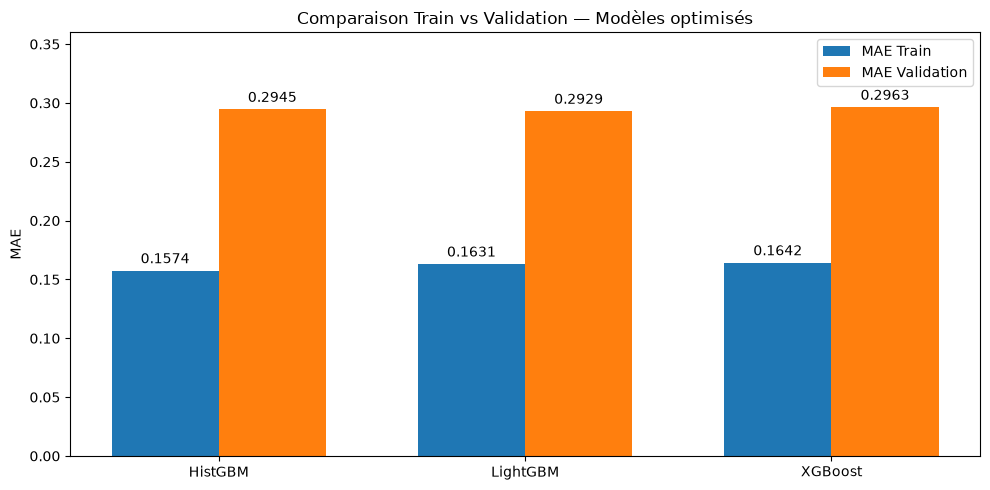

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Résultats des trois modèles optimisés
df_gap = pd.DataFrame({
    "Modele": ["HistGBM", "LightGBM", "XGBoost"],
    "Train": [
        mae_train_opt,
        mae_train_lgbm_opt,
        mae_train_xgb_opt
    ],
    "Validation": [
        mae_val_opt,
        mae_val_lgbm_opt,
        mae_val_xgb_opt
    ]
})

# Positions des barres
x = np.arange(len(df_gap))
largeur = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

barres_train = ax.bar(
    x - largeur / 2,
    df_gap["Train"],
    largeur,
    label="MAE Train"
)

barres_val = ax.bar(
    x + largeur / 2,
    df_gap["Validation"],
    largeur,
    label="MAE Validation"
)

# Valeurs sur les barres
ax.bar_label(barres_train, fmt="%.4f", padding=3)
ax.bar_label(barres_val, fmt="%.4f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(df_gap["Modele"])

ax.set_ylabel("MAE")
ax.set_title(
    "Comparaison Train vs Validation — Modèles optimisés"
)

ax.legend()
ax.set_ylim(0, 0.36)

plt.tight_layout()

plt.savefig(
    reports_dir / "comparaison_gap_3_modeles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
import optuna

from catboost import CatBoostRegressor
from sklearn.model_selection import cross_val_score

def objective_catboost(trial):

    # 1. Hyperparamètres proposés par Optuna
    params = {
        "iterations": trial.suggest_int(
            "iterations", 200, 800, step=100
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.2, log=True
        ),

        "depth": trial.suggest_int(
            "depth", 4, 8
        ),

        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg", 1.0, 10.0, log=True
        )
    }

    # 2. Construire CatBoost
    modele = CatBoostRegressor(
        **params,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )

    # 3. Validation croisée
    scores = cross_val_score(
        modele,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    # 4. Transformer les scores en MAE positives
    mae_folds = -scores

    # 5. Enregistrer la dispersion
    trial.set_user_attr(
        "mae_std",
        float(mae_folds.std())
    )

    # 6. Retourner la MAE moyenne
    return float(mae_folds.mean())

In [23]:
sampler_cat = optuna.samplers.TPESampler(seed=42)

study_catboost = optuna.create_study(
    direction="minimize",
    sampler=sampler_cat,
    study_name="optimisation_catboost"
)

study_catboost.optimize(
    objective_catboost,
    n_trials=20
)

print("\nMeilleure MAE moyenne CV :")
print(round(study_catboost.best_value, 4))

print("\nMeilleurs hyperparamètres :")
for param, valeur in study_catboost.best_params.items():
    print(f"{param} : {valeur}")

[I 2026-11-10 13:37:34,184] A new study created in memory with name: optimisation_catboost
[I 2026-11-10 13:37:53,066] Trial 0 finished with value: 0.29764293890896043 and parameters: {'iterations': 400, 'learning_rate': 0.1785436060870726, 'depth': 7, 'l2_leaf_reg': 3.968793330444372}. Best is trial 0 with value: 0.29764293890896043.
[I 2026-11-10 13:37:57,987] Trial 1 finished with value: 0.3833267674569566 and parameters: {'iterations': 300, 'learning_rate': 0.02864339657822303, 'depth': 4, 'l2_leaf_reg': 7.348118405270449}. Best is trial 0 with value: 0.29764293890896043.
[I 2026-11-10 13:38:07,014] Trial 2 finished with value: 0.3130900440437934 and parameters: {'iterations': 600, 'learning_rate': 0.10211806418789517, 'depth': 4, 'l2_leaf_reg': 9.330606024425668}. Best is trial 0 with value: 0.29764293890896043.
[I 2026-11-10 13:38:17,240] Trial 3 finished with value: 0.3363321313106964 and parameters: {'iterations': 700, 'learning_rate': 0.03261137469244295, 'depth': 4, 'l2_leaf_


Meilleure MAE moyenne CV :
0.2901

Meilleurs hyperparamètres :
iterations : 800
learning_rate : 0.09638924565901015
depth : 8
l2_leaf_reg : 2.453554179189145


In [24]:
historique_catboost = study_catboost.trials_dataframe()

historique_catboost.to_csv(
    reports_dir / "optuna_catboost_trials.csv",
    index=False
)

display(
    historique_catboost
    .sort_values("value")
    .head(5)
)

,number,value,datetime_start,datetime_complete,duration,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,user_attrs_mae_std,system_attrs_tpe:relative_params:0,state
18,18,0.290097,2026-11-10 13:43:08.477410,2026-11-10 13:43:41.672662,0 days 00:00:33.195252,8,800,2.453554,0.096389,0.007171,"{""depth"": 8, ""iterations"": 800, ""l2_leaf_reg"":...",COMPLETE
16,16,0.290380,2026-11-10 13:42:00.079638,2026-11-10 13:42:33.796284,0 days 00:00:33.716646,8,800,2.233524,0.120995,0.007250,"{""depth"": 8, ""iterations"": 800, ""l2_leaf_reg"":...",COMPLETE
15,15,0.290617,2026-11-10 13:41:25.488124,2026-11-10 13:42:00.078197,0 days 00:00:34.590073,8,800,2.253370,0.094230,0.006671,"{""depth"": 8, ""iterations"": 800, ""l2_leaf_reg"":...",COMPLETE
11,11,0.291169,2026-11-10 13:39:52.958499,2026-11-10 13:40:13.791998,0 days 00:00:20.833499,7,700,4.806661,0.129975,0.007343,"{""depth"": 7, ""iterations"": 700, ""l2_leaf_reg"":...",COMPLETE
10,10,0.291657,2026-11-10 13:39:22.783650,2026-11-10 13:39:52.957101,0 days 00:00:30.173451,8,700,5.233105,0.154907,0.006413,"{""depth"": 8, ""iterations"": 700, ""l2_leaf_reg"":...",COMPLETE


In [25]:
from catboost import CatBoostRegressor
from time import perf_counter

# 1. Récupérer les meilleurs hyperparamètres
best_params_cat = study_catboost.best_params

# 2. Construire un nouveau CatBoost
catboost_optimise = CatBoostRegressor(
    **best_params_cat,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

# 3. Entraîner sur 100 % du Train
debut = perf_counter()

catboost_optimise.fit(X_train, y_train)

temps_cat_opt = perf_counter() - debut

# 4. Prédictions
y_pred_train_cat_opt = catboost_optimise.predict(X_train)
y_pred_val_cat_opt = catboost_optimise.predict(X_val)

# 5. Afficher les informations
print(f"Temps d'entraînement : {temps_cat_opt:.2f} secondes")

print("\nMeilleurs hyperparamètres :")
print(best_params_cat)

print("\nPremières prédictions :")
print(y_pred_val_cat_opt[:5])

print("\nValeurs réelles :")
print(y_val.iloc[:5].values)

Temps d'entraînement : 14.03 secondes

Meilleurs hyperparamètres :
{'iterations': 800, 'learning_rate': 0.09638924565901015, 'depth': 8, 'l2_leaf_reg': 2.453554179189145}

Premières prédictions :
[1.80666747 1.23256841 2.48767412 3.10470002 1.22756589]

Valeurs réelles :
[1.554 0.933 2.291 3.167 1.125]


In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

import pandas as pd

# Évaluation sur Train
mae_train_cat_opt = mean_absolute_error(
    y_train, y_pred_train_cat_opt
)

rmse_train_cat_opt = root_mean_squared_error(
    y_train, y_pred_train_cat_opt
)

r2_train_cat_opt = r2_score(
    y_train, y_pred_train_cat_opt
)

# Évaluation sur Validation externe
mae_val_cat_opt = mean_absolute_error(
    y_val, y_pred_val_cat_opt
)

rmse_val_cat_opt = root_mean_squared_error(
    y_val, y_pred_val_cat_opt
)

r2_val_cat_opt = r2_score(
    y_val, y_pred_val_cat_opt
)

# Tableau des métriques
resultats_cat_opt = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [
        mae_train_cat_opt,
        rmse_train_cat_opt,
        r2_train_cat_opt
    ],
    "Validation": [
        mae_val_cat_opt,
        rmse_val_cat_opt,
        r2_val_cat_opt
    ]
})

display(resultats_cat_opt.round(4))

print(
    f"\nMAE Validation : "
    f"{mae_val_cat_opt * 100000:,.2f} $"
)

,Métrique,Train,Validation
0,MAE,0.1720,0.2847
1,RMSE,0.2427,0.4439
2,R²,0.9559,0.8528



MAE Validation : 28,470.70 $


In [27]:
import pandas as pd
import json
from pathlib import Path

# Localiser le projet
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Résumé des résultats CatBoost
resume_catboost = pd.DataFrame([{
    "Modele": "CatBoost_optimise",
    "Nombre_essais": len(study_catboost.trials),
    "MAE_CV": study_catboost.best_value,
    "MAE_Train": mae_train_cat_opt,
    "MAE_Validation": mae_val_cat_opt,
    "RMSE_Validation": rmse_val_cat_opt,
    "R2_Validation": r2_val_cat_opt,
    "Temps_entrainement_s": temps_cat_opt
}])

display(resume_catboost.round(4))

# Sauvegarder les métriques
resume_catboost.to_csv(
    reports_dir / "optimisation_catboost_resume.csv",
    index=False
)

# Sauvegarder les hyperparamètres
with open(
    reports_dir / "catboost_best_params.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        study_catboost.best_params,
        f,
        indent=4
    )

# Actualiser la comparaison globale
chemin_comparaison = (
    reports_dir / "comparaison_modeles_optimises.csv"
)

comparaison_optimisee = pd.read_csv(chemin_comparaison)

# Supprimer une éventuelle ancienne entrée CatBoost
comparaison_optimisee = comparaison_optimisee[
    comparaison_optimisee["Modele"] != "CatBoost"
]

# Ajouter CatBoost
nouveau_resultat = pd.DataFrame([{
    "Modele": "CatBoost",
    "MAE_CV": study_catboost.best_value,
    "MAE_Validation": mae_val_cat_opt,
    "RMSE_Validation": rmse_val_cat_opt,
    "R2_Validation": r2_val_cat_opt,
    "Temps_s": temps_cat_opt
}])

comparaison_optimisee = pd.concat(
    [comparaison_optimisee, nouveau_resultat],
    ignore_index=True
)

comparaison_optimisee = (
    comparaison_optimisee
    .sort_values("MAE_Validation")
    .reset_index(drop=True)
)

display(comparaison_optimisee.round(4))

# Enregistrer le classement
comparaison_optimisee.to_csv(
    chemin_comparaison,
    index=False
)

print("CatBoost ajouté à la comparaison.")

,Modele,Nombre_essais,MAE_CV,MAE_Train,MAE_Validation,RMSE_Validation,R2_Validation,Temps_entrainement_s
0,CatBoost_optimise,20,0.2901,0.172,0.2847,0.4439,0.8528,14.0276


,Modele,MAE_CV,MAE_Validation,RMSE_Validation,R2_Validation,Temps_s
0,CatBoost,0.2901,0.2847,0.4439,0.8528,14.0276
1,LightGBM,0.2954,0.2929,0.4581,0.8432,2.1608
2,HistGBM,0.2957,0.2945,0.4600,0.8419,1.1612
3,XGBoost,0.2983,0.2963,0.4580,0.8432,1.6404


CatBoost ajouté à la comparaison.


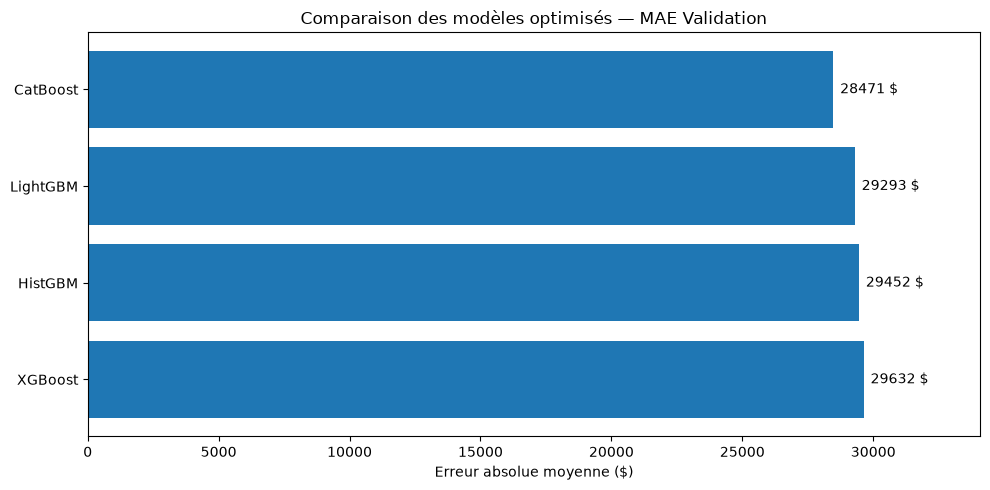

In [28]:
import matplotlib.pyplot as plt

# Trier les modèles par MAE
df_graph = comparaison_optimisee.sort_values(
    "MAE_Validation",
    ascending=True
)

# Convertir la MAE en dollars
mae_dollars = df_graph["MAE_Validation"] * 100000

fig, ax = plt.subplots(figsize=(10, 5))

barres = ax.barh(
    df_graph["Modele"],
    mae_dollars
)

ax.bar_label(
    barres,
    fmt="%.0f $",
    padding=5
)

ax.invert_yaxis()

ax.set_xlabel("Erreur absolue moyenne ($)")
ax.set_title(
    "Comparaison des modèles optimisés — MAE Validation"
)

ax.set_xlim(0, mae_dollars.max() * 1.15)

plt.tight_layout()

plt.savefig(
    reports_dir / "comparaison_4_modeles_optimises.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()